In [6]:
from IPython.display import display, Latex, Markdown # for displaying Mardown/LaTeX-written expressions in Jupyter Notebook
import numpy as np #for maths functionality
import matplotlib.pyplot as plt #for visualising data

In [7]:
def Lambda(m):
    nodes = np.linspace(-1, 1, m+1) # create m+1 equally-spaced nodes on the interval [-1,1]
    x_vals = np.linspace(-1, 1, 100) # create 100 equally-spaced x values on the interval [-1,1]
    
    def L(j, x): # return j-th Lagrange basis of x
        return np.prod([(x - nodes[k]) / (nodes[j] - nodes[k]) for k in range(m+1) if k != j])
    
    result = max([sum([abs(L(j,x)) for j in range(m+1)]) for x in x_vals]) #compute Lebesgue constant
    
    return result

ans = Lambda(10)
display(Latex(fr'$\Lambda_{{10}} \approx {ans:.2f}$.')) 

<IPython.core.display.Latex object>

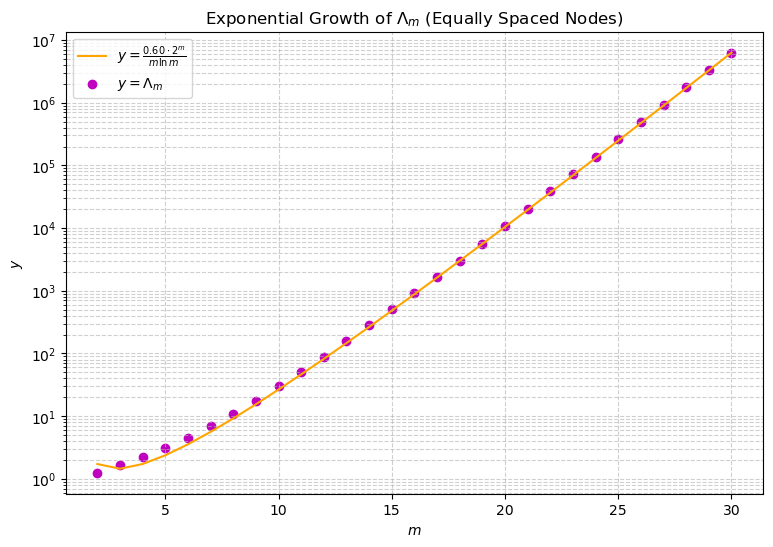

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define m 
m_vals = np.arange(2, 31, step=1)

# 2. Calculate actual values
y1_vals = np.array([Lambda(m) for m in m_vals])

# 3. Calculate theoretical growth 
y2_raw = (2**m_vals) / (m_vals * np.log(m_vals))

# 4. Calculate scaling factor 
scaling_factor = y1_vals[-1] / y2_raw[-1]
y2_vals = scaling_factor * y2_raw

# 5. Plotting
plt.figure(figsize=(9, 6))
plt.plot(m_vals, y2_vals, color='orange', 
         label=rf'$y = \frac{{{scaling_factor:.2f} \cdot 2^m}}{{m \ln m}}$')

plt.scatter(m_vals, y1_vals, color='m', label=r'$y=\Lambda_m$')

plt.title(r'Exponential Growth of $\Lambda_m$ (Equally Spaced Nodes)')
plt.yscale("log")
plt.ylabel(r'$y$')
plt.xlabel(r'$m$')
plt.grid(True, which="both", linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In this context, the Lebesgue constant acts as a condition number for the interpolation operator. 

Well-posedness: A problem is well-posed if its solution exists, is unique, and changes continuously with the initial data (stability). We can see from the graph that Lebesgue constant is very large for large m, then the numerical problem becomes ill-conditioned for uniform nodes as m increases.- not well-posedness

Stability: Since $\Lambda_m \sim \frac{2^m}{m \log m}$ grows exponentially, even for a modest $m=30$, $\Lambda_m$ is already in the millions. This means even a very small error can be amplified so significantly that the resulting plot becomes meaningless. -unstable

Convergence: increase the number of nodes ($m \to \infty$), the interpolating polynomial would eventually "snap" to the shape of the function. However, the Lebesgue Inequality tells us:$$\|f - P_m\|_\infty \leq (1 + \Lambda_m) \|f - P_m^*\|_\infty$$Where $P_m^*$ is the best possible polynomial approximation.For equally spaced nodes, the growth of $\Lambda_m$ is so fast that it often outpaces the decay of the approximation error $\|f - P_m^*\|_\infty$. This leads to the Runge Phenomenon, where the error actually increases at the edges of the interval as you add more points, preventing convergence.-not convergent

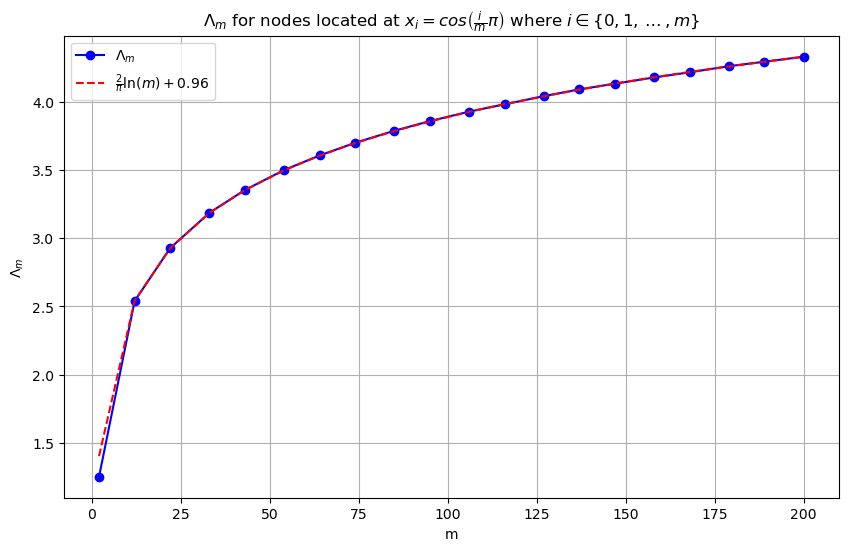

In [24]:
import numpy as np
import matplotlib.pyplot as plt

def LambdaC(m):
    nodes = np.cos([i*np.pi/m for i in range(m+1)])
    
    # Fine grid to find the maximum of the Lebesgue function
    x_fine = np.linspace(-1, 1, 1000)
    lebesgue_func = np.zeros_like(x_fine)
    
    for i in range(m + 1):
        # Calculate the i-th Lagrange basis polynomial
        li = np.ones_like(x_fine)
        for j in range(m + 1):
            if i != j:
                li *= (x_fine - nodes[j]) / (nodes[i] - nodes[j])
        lebesgue_func += np.abs(li)
        
    return np.max(lebesgue_func)

# Parameters
m_values = np.linspace(2, 200, 20, dtype=int)
lebesgue_constants = [LambdaC(m) for m in m_values]

# Theoretical comparison: (2/pi) * ln(m) + Constant
# We add a constant (e.g., 0.96) to align the curves for visualization
theoretical = (2 / np.pi) * np.log(m_values) + 0.96

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(m_values, lebesgue_constants, 'bo-', label='$\Lambda_m$')
plt.plot(m_values, theoretical, 'r--', label='$\\frac{2}{\pi}\ln(m) + 0.96$')
plt.xlabel('m')
plt.ylabel('$\Lambda_m$')
plt.title(r'$\Lambda_m$ for nodes located at $x_i = cos \left( \frac{i}{m} \pi \right)$ where $i \in \{0,1,\dots, m\}$')
plt.legend()
plt.grid(True)
plt.show()

The condition number grows very slowly showing that the problem is well-conditioned.

In [25]:
def recursive_f(f, nodes): 
    if len(nodes) == 1: #base case
        return f(nodes[0])
    n = len(nodes) - 1
    return (recursive_f(f, nodes[1:]) - recursive_f(f, nodes[:n]))/(nodes[n] - nodes[0]) # inductive step

f = np.sin
nodes = [0, 1, 2, 3]
ans = recursive_f(f, nodes)
display(Latex(fr'$f[0, 1, 2, 3]= {ans:.4f}$ (to 4 d.p.)'))

<IPython.core.display.Latex object>

In [26]:
def qk(f, nodes, k, x):
    if k == 0:
        return f(nodes[0])
    return qk(f, nodes[:k], k-1, x) + recursive_f(f, nodes)*np.prod([x-nodes[j] for j in range(k)])   

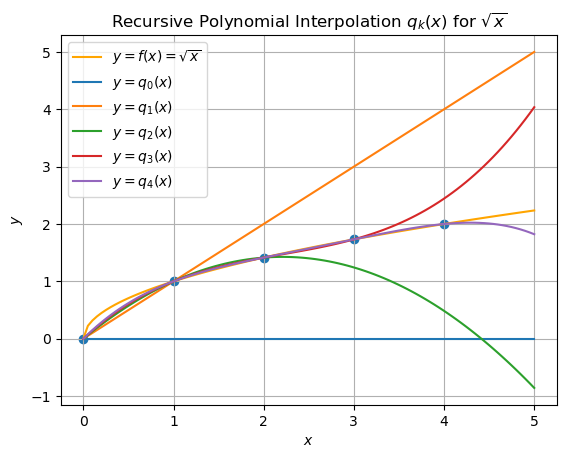

In [34]:
f = np.sqrt

x_vals = np.linspace(0, 5, 100)

nodes = np.arange(0,5,step=1)

f_vals = f(x_vals)

plt.plot(x_vals, f_vals, color='orange', label=r'$ y= f(x) = \sqrt{x}$') # plot f(x) 

plt.scatter(nodes, f(nodes)) #plot nodes

for k in range(5):
    qk_vals = [qk(f, nodes[:k+1], k, x) for x in x_vals]
    plt.plot(x_vals, qk_vals, label=fr'$ y= q_{k}(x)$')

#beautify plot
plt.title(r'Recursive Polynomial Interpolation $q_k(x)$ for $\sqrt{x}$')
plt.ylabel(r'$y$')
plt.xlabel(r'$x$')
plt.grid(True)
plt.legend()
plt.show()

In [38]:
def midpoint(f, a, b): 
    return (b-a)*f((a+b)/2)

def trapezoidal(f, a, b):
    return (b-a)*(f(a) + f(b))/2 

def simpson(f, a, b):
    return (b-a)*(f(a) + 4*f((a+b)/2) + f(b))/6

In [40]:
import numpy as np

f = lambda x: np.tanh(x)

exact = np.log(np.cosh(1))

I0_f = midpoint(f, 0, 1) #compute midpoint quadrature
  
I1_f = trapezoidal(f, 0, 1) #compute trapezoidal quadrature

I2_f = simpson(f, 0, 1) # compute Cavalieri-Simpson quadrature

methods = [
    ("Midpoint", I0_f ),
    ("Trapezoidal",I1_f ),
    ("Simpson", I2_f)
]

print(f"{'Method':<12} | {'Value':<10} | {'Error':<10}")
print("-" * 35)
for name, val in methods:
    error = abs(val - exact)
    print(f"{name:<12} | {val:.3f}      | {error:.2e}")

Method       | Value      | Error     
-----------------------------------
Midpoint     | 0.462      | 2.83e-02
Trapezoidal  | 0.381      | 5.30e-02
Simpson      | 0.435      | 1.23e-03


Comment: Simpson's rule is significantly more accurate than the other two because it uses a quadratic approximation of the integrand, whereas Midpoint and Trapezoidal use constant and linear approximations, respectively. Note that the Midpoint error is roughly half the Trapezoidal error, which is consistent with errors provided in lecture notes.

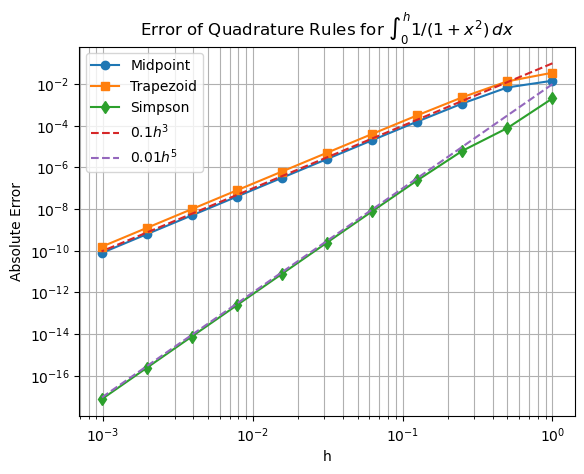

In [51]:
h_vals = 2.0**(-np.arange(0, 11))
f_q = lambda x: 1 / (1 + x**2)
exact_vals = np.arctan(h_vals)

err_m = [abs(midpoint(f_q, 0, h) - np.arctan(h)) for h in h_vals]
err_t = [abs(trapezoidal(f_q, 0, h) - np.arctan(h)) for h in h_vals]
err_s = [abs(simpson(f_q, 0, h) - np.arctan(h)) for h in h_vals]

# Plotting
import matplotlib.pyplot as plt
plt.loglog(h_vals, err_m, 'o-', label='Midpoint')
plt.loglog(h_vals, err_t, 's-', label='Trapezoid')
plt.loglog(h_vals, err_s, 'd-', label='Simpson')
plt.loglog(h_vals, 0.1*h_vals**3, '--', label='$0.1h^3$')
plt.loglog(h_vals, 0.01*h_vals**5, '--', label='$0.01h^5$')
plt.xlabel('h')
plt.ylabel('Absolute Error')
plt.title(r'Error of Quadrature Rules for $\int_0^h 1/(1+x^2) \, dx$')
plt.legend()
plt.grid(True, which="both", ls="-")
plt.show()

Midpoint & Trapezoid: The slopes on the log-log plot align with $h^3$.   
Simpson:The slope aligns with $h^5$.   
Interpretation: The Midpoint and Trapezoid rules are exact for polynomials of degree 1. Simpson is exact for polynomials of degree 3. The symmetry of the Midpoint rule gives it the same order as the Trapezoid rule but with a smaller error constant.   
From lecture, Midpoint Error: $E_M = -\frac{h^3}{24} f''(\xi)$  
Trapezoid Error: $E_T = \frac{h^3}{12} f''(\xi)$  
Simpson error:$E_S = \frac{h^5}{2880} f^{(4)}(\xi)$  
order of h matches what we have observed from the graph.

In [56]:
import numpy as np
import pandas as pd

h_vals = 2.0**(-np.arange(11))
f_q = lambda x: 1 / (1 + x**2)
exact_vals = np.arctan(h_vals)

midpoint_errors = [abs(midpoint(f_q, 0, h) - np.arctan(h)) for h in h_vals]
trapezoidal_errors = [abs(trapezoidal(f_q, 0, h) - np.arctan(h)) for h in h_vals]
simpson_errors = [abs(simpson(f_q, 0, h) - np.arctan(h)) for h in h_vals]

def get_eoc(h_list, error_list):
    eocs = [np.nan]
    for i in range(1, len(h_list)):
        p = np.log(error_list[i] / error_list[i-1]) / np.log(h_list[i] / h_list[i-1])
        eocs.append(round(p, 3))
    return eocs

eoc_m = get_eoc(h_vals, midpoint_errors)
eoc_t = get_eoc(h_vals, trapezoidal_errors)
eoc_s = get_eoc(h_vals, simpson_errors)

df = pd.DataFrame({
    'h': h_vals,
    'Midpoint EOC': eoc_m,
    'Trapezoid EOC': eoc_t,
    'Simpson EOC': eoc_s
})

print(df.to_string(index=False))

       h  Midpoint EOC  Trapezoid EOC  Simpson EOC
1.000000           NaN            NaN          NaN
0.500000         1.073          1.375        4.729
0.250000         2.562          2.549        3.638
0.125000         2.889          2.881        4.713
0.062500         2.972          2.970        4.930
0.031250         2.993          2.992        4.983
0.015625         2.998          2.998        4.996
0.007812         3.000          3.000        4.999
0.003906         3.000          3.000        5.000
0.001953         3.000          3.000        5.000
0.000977         3.000          3.000        5.005
